# Phase 5 — Customer Segmentation

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)
RANDOM_STATE = 42

PROC_DIR = Path('../data/processed')
cf = pd.read_csv(PROC_DIR / 'customer_features.csv')
print('Loaded shape:', cf.shape)
cf.head()

Loaded shape: (36950, 12)


,customer_unique_id,total_orders,total_spending,avg_basket_size,avg_order_value,recency_days,frequency,monetary_value,customer_tenure_days,days_since_last_purchase,avg_review_rating,preferred_payment_method
0,0000366f3b9a7992bf8c76cfdf3221e2,1,141.90,1.0,141.90,65,1,141.90,65,65,5.0,credit_card
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,27.19,1.0,27.19,157,1,27.19,157,157,4.0,credit_card
2,0004bd2a26a76fe21f786e4fbd80607f,1,166.98,1.0,166.98,219,1,166.98,219,219,4.0,credit_card
3,0005e1862207bf6ccc02e4228effd9a0,1,150.12,1.0,150.12,615,1,150.12,615,615,4.0,credit_card
4,000a5ad9c4601d2bbdd9ed765d5213b3,1,91.28,1.0,91.28,396,1,91.28,396,396,4.0,credit_card


## Preprocessing

In [3]:
cluster_features = ['recency_days', 'frequency', 'monetary_value',
                    'avg_order_value', 'avg_basket_size']

X = cf[cluster_features].copy().fillna(0)

# log1p on monetary/spending fields to tame right skew
for col in ['monetary_value', 'avg_order_value']:
    X[col] = np.log1p(X[col])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('X_scaled shape:', X_scaled.shape)

X_scaled shape: (36950, 5)


## Choosing k — Elbow Method & Silhouette Score

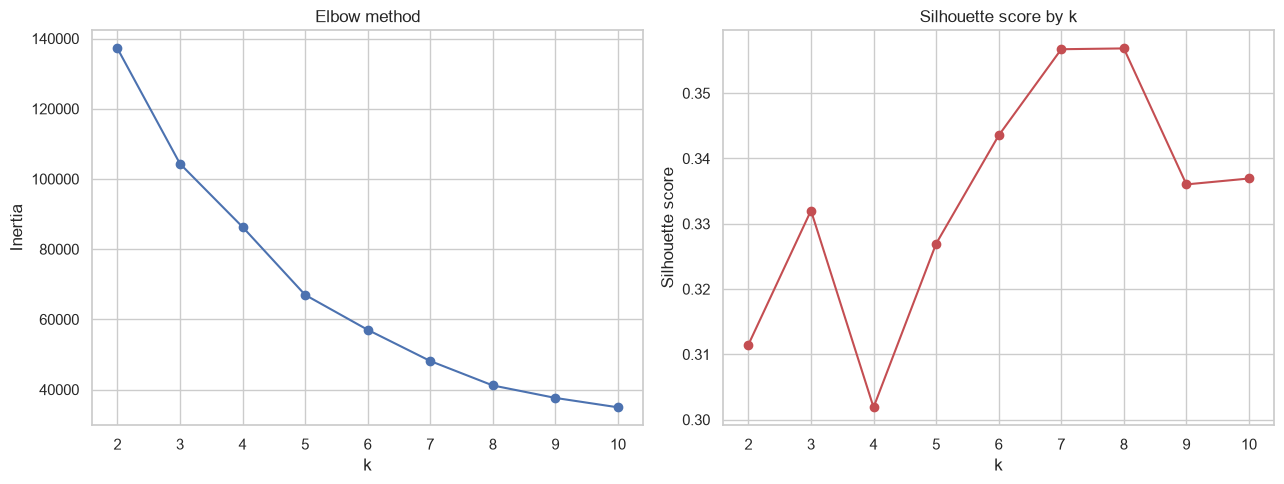

k=2: silhouette=0.3115
k=3: silhouette=0.3320
k=4: silhouette=0.3019
k=5: silhouette=0.3270
k=6: silhouette=0.3435
k=7: silhouette=0.3567
k=8: silhouette=0.3569
k=9: silhouette=0.3360
k=10: silhouette=0.3369


In [4]:
k_range = range(2, 11)
inertias = []
silhouettes = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(list(k_range), inertias, marker='o')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow method')

axes[1].plot(list(k_range), silhouettes, marker='o', color='#C44E52')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Silhouette score')
axes[1].set_title('Silhouette score by k')
plt.tight_layout()
plt.show()

for k, s in zip(k_range, silhouettes):
    print(f'k={k}: silhouette={s:.4f}')

## K-Means

In [5]:
K = 5
kmeans = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10)
cf['cluster_kmeans'] = kmeans.fit_predict(X_scaled)

kmeans_silhouette = silhouette_score(X_scaled, cf['cluster_kmeans'])
print(f'K-Means silhouette score (k={K}): {kmeans_silhouette:.4f}')
cf['cluster_kmeans'].value_counts().sort_index()

K-Means silhouette score (k=5): 0.3270


cluster_kmeans
0    10828
1      622
2    13256
3      761
4    11483
Name: count, dtype: int64

## Agglomerative Clustering (bonus)

Same k=5, for comparison against K-Means. Agglomerative clustering doesn't
assume spherical clusters the way K-Means does, so differences here can
reveal whether K-Means' spherical assumption is distorting the segments.

In [6]:
# agglo = AgglomerativeClustering(n_clusters=K, linkage='ward')
# cf['cluster_agglo'] = agglo.fit_predict(X_scaled)

# agglo_silhouette = silhouette_score(X_scaled, cf['cluster_agglo'])
# print(f'Agglomerative silhouette score (k={K}): {agglo_silhouette:.4f}')
# print(f'K-Means silhouette score (k={K}):       {kmeans_silhouette:.4f}')
# cf['cluster_agglo'].value_counts().sort_index()

In [7]:
import numpy as np
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import pandas as pd

sample_size = 5000

# Random sample indices
np.random.seed(42)

indices = np.random.choice(
    X_scaled.shape[0],
    size=min(sample_size, X_scaled.shape[0]),
    replace=False
)

# Sample only 5000 rows
X_agglo = X_scaled[indices]

print("Original shape:", X_scaled.shape)
print("Sample shape:", X_agglo.shape)

# Agglomerative clustering
agglo = AgglomerativeClustering(
    n_clusters=K,
    linkage='ward'
)

agglo_labels = agglo.fit_predict(X_agglo)

agglo_silhouette = silhouette_score(
    X_agglo,
    agglo_labels
)

print(f"Agglomerative Silhouette: {agglo_silhouette:.4f}")

print(pd.Series(agglo_labels).value_counts().sort_index())

Original shape: (36950, 5)
Sample shape: (5000, 5)
Agglomerative Silhouette: 0.3054
0    2100
1     481
2      87
3    1365
4     967
Name: count, dtype: int64


In [8]:
print(type(X_scaled))
print(X_scaled.shape)
print(type(X_agglo))
print(X_agglo.shape)

<class 'numpy.ndarray'>
(36950, 5)
<class 'numpy.ndarray'>
(5000, 5)


## DBSCAN (bonus)

DBSCAN doesn't take k as an input — it needs `eps` (neighborhood radius) and
`min_samples`. We pick `eps` using a k-distance plot: sort each point's
distance to its k-th nearest neighbor and look for the "knee" where distance
starts rising sharply — that's a reasonable `eps`.

Unlike K-Means/Agglomerative, DBSCAN can produce **noise points** (label
`-1`, not assigned to any cluster) and won't necessarily produce 5 clusters
— that's expected, not a bug; density-based clustering finds however many
dense regions actually exist.

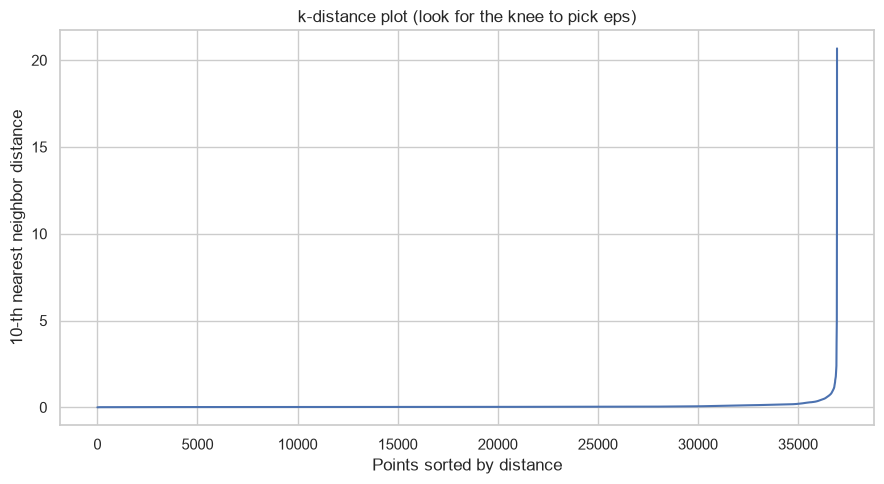

In [9]:
min_samples = 10
neighbors = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)
distances, _ = neighbors.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 5))
plt.plot(k_distances)
plt.xlabel('Points sorted by distance')
plt.ylabel(f'{min_samples}-th nearest neighbor distance')
plt.title('k-distance plot (look for the knee to pick eps)')
plt.tight_layout()
plt.show()

In [10]:
# Set EPS by eyeballing the knee in the plot above. Adjust this value for
# your actual data if the knee sits somewhere else.
EPS = float(np.percentile(k_distances, 90))
print(f'Using eps={EPS:.3f} (90th percentile of k-distances, as a starting point)')

dbscan = DBSCAN(eps=EPS, min_samples=min_samples)
cf['cluster_dbscan'] = dbscan.fit_predict(X_scaled)

n_clusters_dbscan = len(set(cf['cluster_dbscan'])) - (1 if -1 in cf['cluster_dbscan'].values else 0)
n_noise = (cf['cluster_dbscan'] == -1).sum()
print(f'DBSCAN found {n_clusters_dbscan} clusters and {n_noise} noise points ({n_noise/len(cf)*100:.1f}%)')

if n_clusters_dbscan > 1:
    mask = cf['cluster_dbscan'] != -1
    dbscan_silhouette = silhouette_score(X_scaled[mask], cf.loc[mask, 'cluster_dbscan'])
    print(f'DBSCAN silhouette score (excluding noise): {dbscan_silhouette:.4f}')
else:
    print('Not enough clusters found to compute a silhouette score — try a different eps.')

cf['cluster_dbscan'].value_counts().sort_index()

Using eps=0.133 (90th percentile of k-distances, as a starting point)
DBSCAN found 22 clusters and 2825 noise points (7.6%)
DBSCAN silhouette score (excluding noise): -0.0452


cluster_dbscan
-1      2825
 0     31953
 1      1676
 2        70
 3        19
 4        86
 5        94
 6        10
 7        18
 8        18
 9        10
 10       13
 11       13
 12       46
 13       16
 14       14
 15       12
 16       12
 17        7
 18        7
 19        9
 20       10
 21       12
Name: count, dtype: int64

## Visualization — PCA and t-SNE (bonus)

Explained variance ratio: [0.41902013 0.2007039 ], total=61.97%


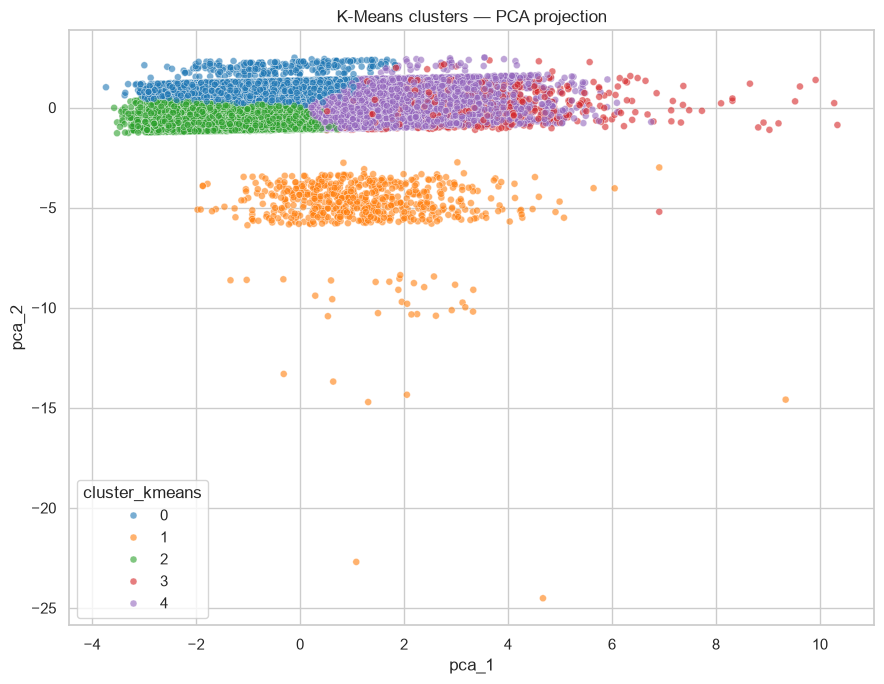

In [11]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
cf['pca_1'] = X_pca[:, 0]
cf['pca_2'] = X_pca[:, 1]

print(f'Explained variance ratio: {pca.explained_variance_ratio_}, '
      f'total={pca.explained_variance_ratio_.sum():.2%}')

fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(data=cf, x='pca_1', y='pca_2', hue='cluster_kmeans', palette='tab10',
                 s=25, alpha=0.6, ax=ax)
ax.set_title('K-Means clusters — PCA projection')
plt.tight_layout()
plt.show()

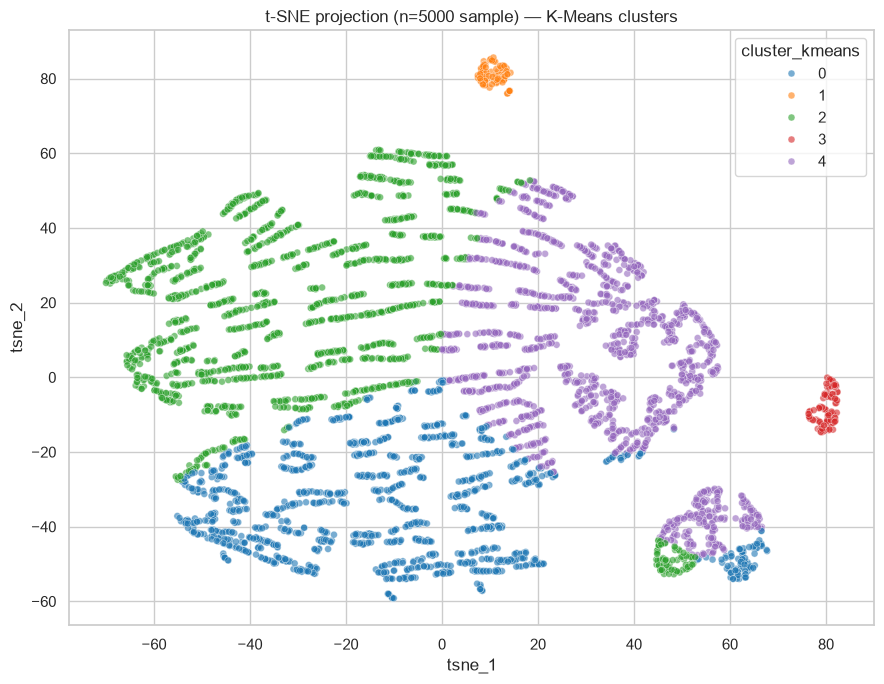

In [12]:
# t-SNE — subsample for speed if the customer base is large (t-SNE scales poorly)
SAMPLE_SIZE = min(5000, len(cf))
sample_idx = cf.sample(SAMPLE_SIZE, random_state=RANDOM_STATE).index

tsne = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=30, init='pca')
X_tsne = tsne.fit_transform(X_scaled[cf.index.get_indexer(sample_idx)])

tsne_df = cf.loc[sample_idx, ['cluster_kmeans']].copy()
tsne_df['tsne_1'] = X_tsne[:, 0]
tsne_df['tsne_2'] = X_tsne[:, 1]

fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(data=tsne_df, x='tsne_1', y='tsne_2', hue='cluster_kmeans', palette='tab10',
                 s=25, alpha=0.6, ax=ax)
ax.set_title(f't-SNE projection (n={SAMPLE_SIZE} sample) — K-Means clusters')
plt.tight_layout()
plt.show()

## Business Deliverables — mapping clusters to personas

In [13]:
profile = cf.groupby('cluster_kmeans')[
    ['recency_days', 'frequency', 'monetary_value', 'avg_order_value',
     'avg_basket_size', 'customer_tenure_days']
].mean().round(2)
profile['n_customers'] = cf['cluster_kmeans'].value_counts().sort_index()
profile

,recency_days,frequency,monetary_value,avg_order_value,avg_basket_size,customer_tenure_days,n_customers
cluster_kmeans,,,,,,,
0,563.36,1.00,90.57,90.57,1.06,563.36,10828
1,333.00,2.07,320.49,155.08,1.19,436.47,622
2,186.64,1.00,71.36,71.36,1.04,186.64,13256
3,330.56,1.00,399.25,398.13,3.81,330.56,761
4,299.49,1.00,319.97,319.97,1.14,299.49,11483


In [14]:
pop_median = cf[['recency_days', 'frequency', 'monetary_value',
                  'avg_order_value', 'customer_tenure_days']].median()

def assign_persona(row):
    if row['monetary_value'] >= pop_median['monetary_value'] and row['frequency'] >= pop_median['frequency']:
        return 'Premium Customers'
    if row['recency_days'] >= 1.5 * pop_median['recency_days']:
        return 'Dormant Customers'
    if row['customer_tenure_days'] <= pop_median['customer_tenure_days'] and row['frequency'] <= 2:
        return 'New Customers'
    if row['frequency'] >= pop_median['frequency'] and row['avg_order_value'] < pop_median['avg_order_value']:
        return 'Bargain Hunters'
    return 'Regular Customers'

profile['persona'] = profile.apply(assign_persona, axis=1)
persona_map = profile['persona'].to_dict()
cf['persona'] = cf['cluster_kmeans'].map(persona_map)

print(profile[['n_customers', 'persona']])
print()
print(cf['persona'].value_counts())

                n_customers            persona
cluster_kmeans                                
0                     10828  Dormant Customers
1                       622  Premium Customers
2                     13256      New Customers
3                       761  Premium Customers
4                     11483  Premium Customers

persona
New Customers        13256
Premium Customers    12866
Dormant Customers    10828
Name: count, dtype: int64


C:\Users\Pavithran\AppData\Local\Temp\ipykernel_29400\1422718429.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=cf, x='persona', y='recency_days', order=persona_order, ax=axes[0], showfliers=False, palette='Set2')
C:\Users\Pavithran\AppData\Local\Temp\ipykernel_29400\1422718429.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=cf, x='persona', y='frequency', order=persona_order, ax=axes[1], showfliers=False, palette='Set2')
C:\Users\Pavithran\AppData\Local\Temp\ipykernel_29400\1422718429.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

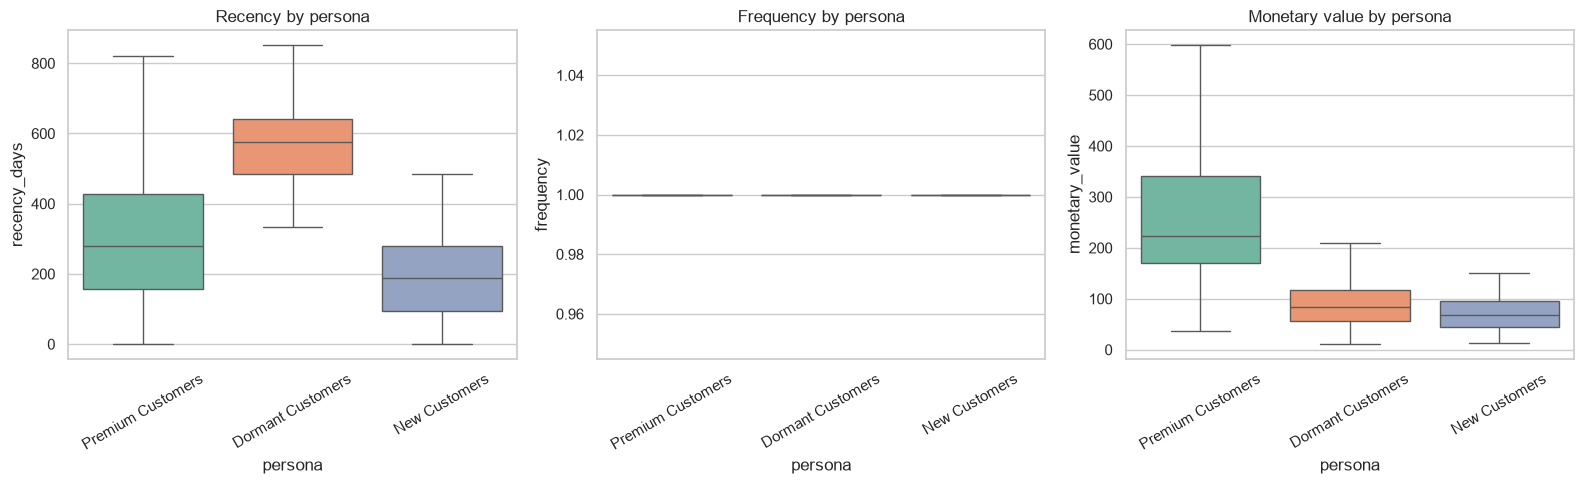

In [15]:
# Visual summary: persona vs. RFM
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
persona_order = cf.groupby('persona')['monetary_value'].mean().sort_values(ascending=False).index

sns.boxplot(data=cf, x='persona', y='recency_days', order=persona_order, ax=axes[0], showfliers=False, palette='Set2')
axes[0].set_title('Recency by persona')
axes[0].tick_params(axis='x', rotation=30)

sns.boxplot(data=cf, x='persona', y='frequency', order=persona_order, ax=axes[1], showfliers=False, palette='Set2')
axes[1].set_title('Frequency by persona')
axes[1].tick_params(axis='x', rotation=30)

sns.boxplot(data=cf, x='persona', y='monetary_value', order=persona_order, ax=axes[2], showfliers=False, palette='Set2')
axes[2].set_title('Monetary value by persona')
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## Save segmented customer data

In [16]:
out_path = PROC_DIR / 'customer_segments.csv'
cf.to_csv(out_path, index=False)
print(f'Saved to {out_path}  ({cf.shape[0]:,} rows, {cf.shape[1]} cols)')

Saved to ..\data\processed\customer_segments.csv  (36,950 rows, 17 cols)
